# Tire Classification Lab: Preprocessing, Blur, Restoration and YOLO

This notebook investigates traditional image processing and a pretrained YOLO classification model for studded vs non-studded tire images. **It does not invent results**: run it with the course dataset and provided tire-specific weights.

## Expected data structure
```text
test/
  studded/
  non-studded/
```
Set the dataset and model paths in the setup cell. Do not upload the dataset images to GitHub.

In [2]:
import zipfile
import os

zip_path = "/content/tire_classification_lab_project.zip"
extract_path = "/content/content/tire_classification_lab_project"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os

for root, dirs, files in os.walk("/content/tire_classification_lab_project"):
    print(root, ":", len(files), "files")

In [4]:
from ultralytics import YOLO

model = YOLO("/content/yolo11n-cls.pt")

print("YOLO model loaded successfully!")

ModuleNotFoundError: No module named 'ultralytics'

In [5]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [6]:
from ultralytics import YOLO

model = YOLO("/content/yolo11n-cls.pt")

print("YOLO model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!


In [10]:
import os

dataset_path = "/content/tire_classification_lab_project"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:3]:
        print(f"{indent}  {file}")

In [11]:
import os

dataset_path = "/content/tire_dataset"

print("Dataset exists:", os.path.exists(dataset_path))
print("\nDataset contents:")

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}  {file}")

Dataset exists: True

Dataset contents:
tire_dataset/


In [12]:
import os

path = "/content/tire_dataset"

print("Contents of tire_dataset:")
print(os.listdir(path))

print("\nTotal image files found:")

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
images = []

for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(extensions):
            images.append(os.path.join(root, f))

print("Total images:", len(images))

for img in images[:10]:
    print(img)

Contents of tire_dataset:
[]

Total image files found:
Total images: 0


In [13]:
import zipfile
import os

zip_path = "/content/dataset_v2_split-20261125T220825Z-1-001.zip"
extract_path = "/content/tire_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed!")

Extraction completed!


In [14]:
import os

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

image_files = []

for root, dirs, files in os.walk("/content/tire_dataset"):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images found:", len(image_files))

for img in image_files[:10]:
    print(img)

Total images found: 500
/content/tire_dataset/dataset_v2_split/train/st/45.jpg
/content/tire_dataset/dataset_v2_split/train/st/911036174_1856046565848425_4249476079571954312_n.jpg
/content/tire_dataset/dataset_v2_split/train/st/93.jpg
/content/tire_dataset/dataset_v2_split/train/st/798040354_876835492176954_2139633164188266031_n.jpg
/content/tire_dataset/dataset_v2_split/train/st/861409324_1100910502733548_6347492871095813813_n.jpg
/content/tire_dataset/dataset_v2_split/train/st/907779828_1649037476706078_5718902380926585412_n.jpg
/content/tire_dataset/dataset_v2_split/train/st/33.jpg
/content/tire_dataset/dataset_v2_split/train/st/70.jpg
/content/tire_dataset/dataset_v2_split/train/st/916382170_1442740581355964_8708613666380718673_n.jpg
/content/tire_dataset/dataset_v2_split/train/st/892059831_1433036245612311_8973038618738262329_n.jpg


In [15]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/tire_dataset")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

# Count images by their parent folder
counts = Counter(p.parent.name for p in images)

print("Image count by folder:")
for folder, count in counts.items():
    print(f"{folder}: {count}")

print("\nExample images:")
for p in images[:10]:
    print(p)

Image count by folder:
st: 250
nst: 250

Example images:
/content/tire_dataset/dataset_v2_split/val/st/94.jpg
/content/tire_dataset/dataset_v2_split/val/st/47.jpg
/content/tire_dataset/dataset_v2_split/val/st/95.jpg
/content/tire_dataset/dataset_v2_split/val/st/885921480_2578495162665840_2534509691923925842_n.jpg
/content/tire_dataset/dataset_v2_split/val/st/13.jpg
/content/tire_dataset/dataset_v2_split/val/st/835950674_39045471345097146_3173462399881084062_n.jpg
/content/tire_dataset/dataset_v2_split/val/st/99.jpg
/content/tire_dataset/dataset_v2_split/val/st/911067141_2242447976649681_5703237175154884896_n.jpg
/content/tire_dataset/dataset_v2_split/val/st/88.jpg
/content/tire_dataset/dataset_v2_split/val/st/18.jpg


Studded image: /content/tire_dataset/dataset_v2_split/val/st/13.jpg
Non-studded image: /content/tire_dataset/dataset_v2_split/val/nst/1.jpg


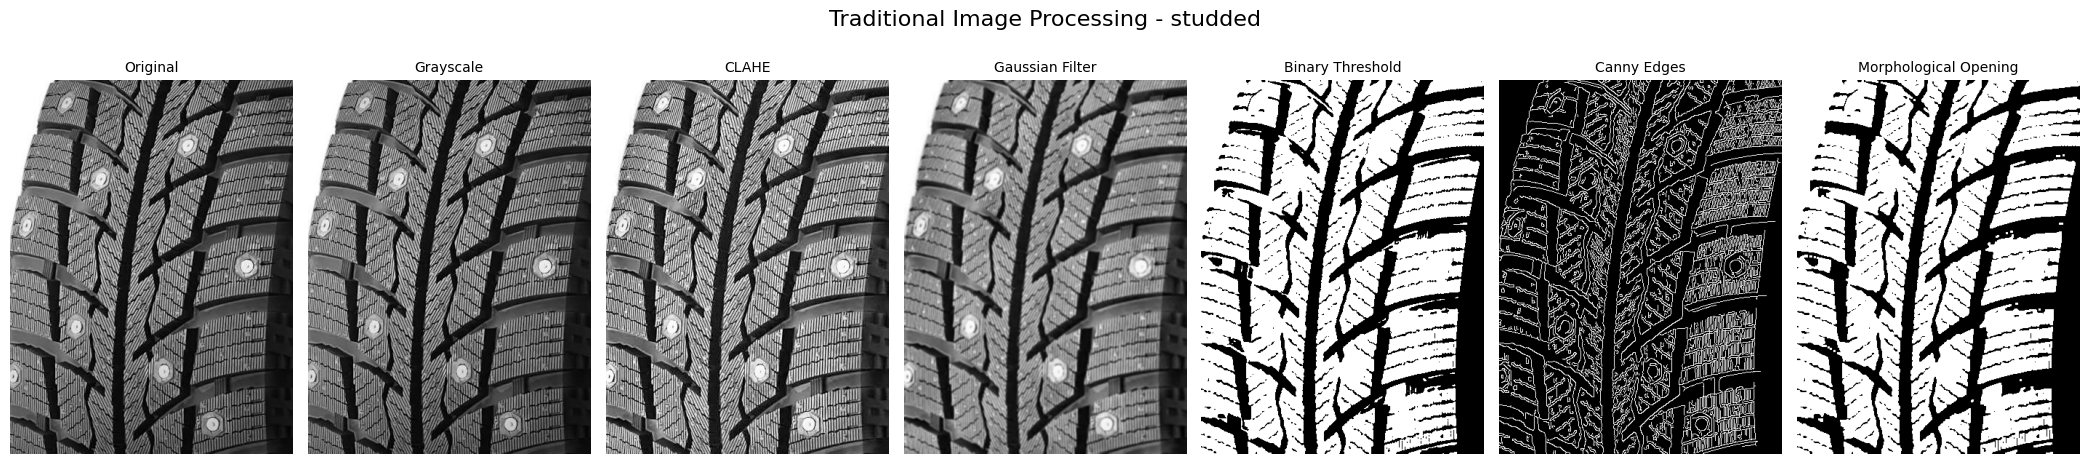

Saved: /content/results/studded_preprocessing.png


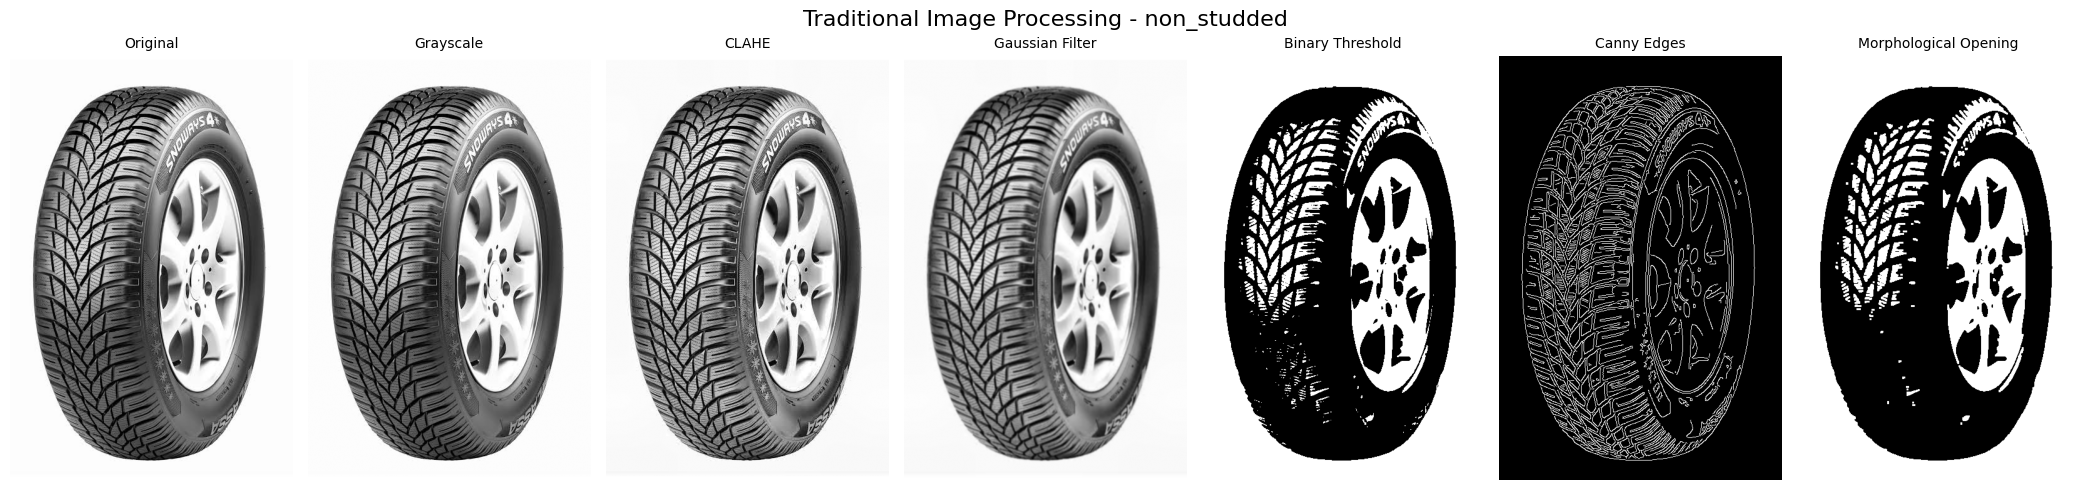

Saved: /content/results/non_studded_preprocessing.png


In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

# Dataset validation folder
base_path = Path("/content/tire_dataset/dataset_v2_split/val")

# Select one image from each class
studded_files = sorted((base_path / "st").glob("*"))
nonstudded_files = sorted((base_path / "nst").glob("*"))

# Filter only image files
valid_ext = {".jpg", ".jpeg", ".png", ".bmp"}

studded_files = [f for f in studded_files if f.suffix.lower() in valid_ext]
nonstudded_files = [f for f in nonstudded_files if f.suffix.lower() in valid_ext]

# Select one example from each category
studded_path = studded_files[0]
nonstudded_path = nonstudded_files[0]

print("Studded image:", studded_path)
print("Non-studded image:", nonstudded_path)

# Create results folder
results_dir = "/content/results"
os.makedirs(results_dir, exist_ok=True)


def preprocess_image(image_path, class_name):

    # Load original image
    original = cv2.imread(str(image_path))
    original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

    # Convert to grayscale
    gray = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)

    # CLAHE contrast enhancement
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced = clahe.apply(gray)

    # Gaussian filtering
    gaussian = cv2.GaussianBlur(
        enhanced,
        (5, 5),
        sigmaX=1
    )

    # Binary thresholding (Otsu)
    _, binary = cv2.threshold(
        gaussian,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Canny edge detection
    edges = cv2.Canny(
        gaussian,
        100,
        200
    )

    # Morphological opening
    kernel = np.ones((3, 3), np.uint8)
    opening = cv2.morphologyEx(
        binary,
        cv2.MORPH_OPEN,
        kernel
    )

    # Store processed images
    processed = [
        original,
        gray,
        enhanced,
        gaussian,
        binary,
        edges,
        opening
    ]

    titles = [
        "Original",
        "Grayscale",
        "CLAHE",
        "Gaussian Filter",
        "Binary Threshold",
        "Canny Edges",
        "Morphological Opening"
    ]

    # Display all results
    fig, axes = plt.subplots(1, 7, figsize=(21, 5))

    for ax, img, title in zip(axes, processed, titles):
        if len(img.shape) == 2:
            ax.imshow(img, cmap="gray")
        else:
            ax.imshow(img)

        ax.set_title(title, fontsize=10)
        ax.axis("off")

    fig.suptitle(
        f"Traditional Image Processing - {class_name}",
        fontsize=16
    )

    plt.tight_layout()

    # Save the figure
    save_path = os.path.join(
        results_dir,
        f"{class_name}_preprocessing.png"
    )

    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved:", save_path)

    return processed


# Process studded tire
studded_results = preprocess_image(
    studded_path,
    "studded"
)

# Process non-studded tire
nonstudded_results = preprocess_image(
    nonstudded_path,
    "non_studded"
)

### Part 1 – Traditional Image Preprocessing

CLAHE noticeably enhances local contrast, making tire tread patterns and small bright details easier to distinguish. However, enhanced contrast does not necessarily make metal studs uniquely identifiable because other bright areas may also become more prominent.

Gaussian filtering reduces high-frequency image information, including fine tread texture and small details. It smooths the image and can reduce noise, but it may also weaken edges and remove details that are important for classification.

Binary thresholding separates pixels based on intensity. It can distinguish bright and dark regions, but it cannot reliably distinguish metal studs from other bright objects or reflections.

Canny edge detection highlights boundaries and tread patterns. It detects many edges in both tire classes, demonstrating that edge information alone is not sufficient to determine whether a tire contains studs.

Morphological opening removes small foreground regions and noise. However, it may also remove thin structures and fine tread details.

Traditional preprocessing is useful for enhancing and analysing image characteristics, but individual operations cannot reliably classify tires because lighting, reflections, tread patterns, image quality and tire appearance vary considerably.

In [17]:
from pathlib import Path

dataset_root = Path("/content/tire_dataset/dataset_v2_split")

print("Dataset splits:")
for split in ["train", "val", "test"]:
    split_path = dataset_root / split
    print(f"\n{split}: exists = {split_path.exists()}")

    if split_path.exists():
        for class_folder in split_path.iterdir():
            if class_folder.is_dir():
                count = len([
                    f for f in class_folder.iterdir()
                    if f.suffix.lower() in {".jpg", ".jpeg", ".png"}
                ])
                print(f"  {class_folder.name}: {count} images")

print("\nYOLO model class names:")
print(model.names)

Dataset splits:

train: exists = True
  st: 175 images
  nst: 175 images

val: exists = True
  st: 38 images
  nst: 38 images

test: exists = True
  st: 37 images
  nst: 37 images

YOLO model class names:
{0: 'nst', 1: 'st'}


Model loaded: {0: 'nst', 1: 'st'}

Total test images: 74
Non-studded: 37
Studded: 37

Prediction completed!

===== YOLO BASELINE RESULTS =====
Accuracy:  0.9054
Precision: 0.8409
Recall:    1.0000
F1-score:  0.9136

Classification Report:

              precision    recall  f1-score   support

 Non-studded       1.00      0.81      0.90        37
     Studded       0.84      1.00      0.91        37

    accuracy                           0.91        74
   macro avg       0.92      0.91      0.90        74
weighted avg       0.92      0.91      0.90        74

Confusion Matrix:
[[30  7]
 [ 0 37]]


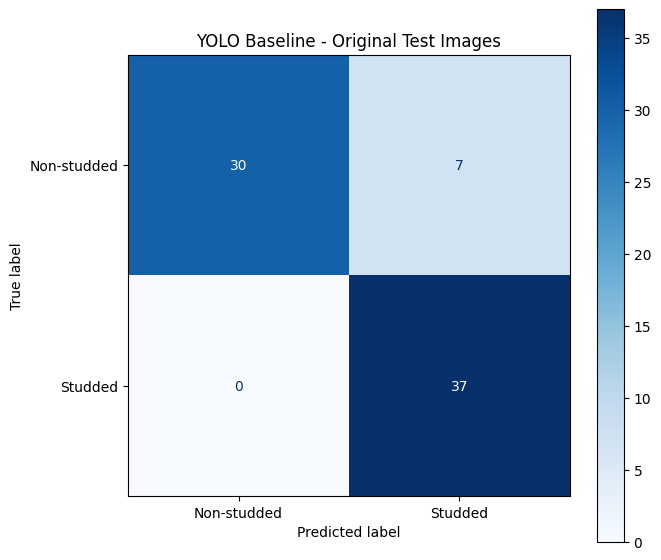


Saved results to /content/results/
Baseline metrics CSV
Prediction CSV
Confusion matrix PNG


In [18]:
# PART 2: YOLO Baseline Evaluation on Original Test Images

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from ultralytics import YOLO
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. Load the provided trained model
# --------------------------------------------------

model = YOLO("/content/best.pt")

print("Model loaded:", model.names)

# --------------------------------------------------
# 2. Locate test images
# --------------------------------------------------

test_path = Path("/content/tire_dataset/dataset_v2_split/test")

class_mapping = {
    "nst": 0,  # non-studded
    "st": 1    # studded
}

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_images = []
true_labels = []

for class_folder in test_path.iterdir():

    if not class_folder.is_dir():
        continue

    class_name = class_folder.name.lower()

    if class_name not in class_mapping:
        continue

    for image_file in class_folder.iterdir():

        if image_file.suffix.lower() in image_extensions:
            test_images.append(str(image_file))
            true_labels.append(class_mapping[class_name])

print("\nTotal test images:", len(test_images))
print("Non-studded:", true_labels.count(0))
print("Studded:", true_labels.count(1))

# --------------------------------------------------
# 3. Predict all test images
# --------------------------------------------------

predicted_labels = []
confidence_scores = []

for image_path in test_images:

    result = model.predict(
        source=image_path,
        verbose=False
    )[0]

    predicted_index = result.probs.top1

    predicted_class_name = model.names[predicted_index].lower()

    predicted_labels.append(class_mapping[predicted_class_name])

    confidence_scores.append(float(result.probs.top1conf))

print("\nPrediction completed!")

# --------------------------------------------------
# 4. Calculate metrics
# --------------------------------------------------

accuracy = accuracy_score(true_labels, predicted_labels)

precision = precision_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

recall = recall_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

f1 = f1_score(
    true_labels,
    predicted_labels,
    zero_division=0
)

print("\n===== YOLO BASELINE RESULTS =====")

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# --------------------------------------------------
# 5. Classification report
# --------------------------------------------------

print("\nClassification Report:\n")

report = classification_report(
    true_labels,
    predicted_labels,
    labels=[0, 1],
    target_names=["Non-studded", "Studded"],
    zero_division=0
)

print(report)

# --------------------------------------------------
# 6. Confusion matrix
# --------------------------------------------------

cm = confusion_matrix(
    true_labels,
    predicted_labels,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

# Plot
fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-studded", "Studded"]
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("YOLO Baseline - Original Test Images")
plt.tight_layout()

# Save figure
os.makedirs("/content/results", exist_ok=True)

plt.savefig(
    "/content/results/yolo_baseline_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 7. Save results as CSV
# --------------------------------------------------

baseline_metrics = pd.DataFrame({
    "Experiment": ["YOLO - Original"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-score": [f1]
})

baseline_metrics.to_csv(
    "/content/results/yolo_baseline_metrics.csv",
    index=False
)

# Save individual predictions
predictions_df = pd.DataFrame({
    "Image": test_images,
    "True_Label": [
        "Non-studded" if label == 0 else "Studded"
        for label in true_labels
    ],
    "Predicted_Label": [
        "Non-studded" if label == 0 else "Studded"
        for label in predicted_labels
    ],
    "Confidence": confidence_scores,
    "Correct": [
        true == pred
        for true, pred in zip(true_labels, predicted_labels)
    ]
})

predictions_df.to_csv(
    "/content/results/yolo_baseline_predictions.csv",
    index=False
)

print("\nSaved results to /content/results/")
print("Baseline metrics CSV")
print("Prediction CSV")
print("Confusion matrix PNG")

### Part 2 – YOLO Baseline Classification

The pretrained YOLO classification model was evaluated on 74 original test images, containing 37 studded and 37 non-studded tires. The model achieved an accuracy of 90.54%, a precision of 84.09%, a recall of 100.00%, and an F1-score of 91.36%.

All 37 studded tires were correctly classified, resulting in 100% recall for the studded class. However, 7 of the 37 non-studded tires were incorrectly classified as studded. The model correctly identified 30 non-studded tires.

The results indicate that the model performs well on this test dataset but is more likely to mistake non-studded tires for studded tires than the reverse. Differences in tread patterns, lighting, reflections, image quality and visual similarities between tire classes may contribute to these errors.

Although the baseline performance is high, the evaluation is limited to 74 test images. Therefore, the results may not represent performance on all tire types or images captured under different real-world conditions.

In [19]:
# PART 3: Motion Blur Simulation

import cv2
import numpy as np
import os
from pathlib import Path
import matplotlib.pyplot as plt

# Original test dataset
original_test_path = Path(
    "/content/tire_dataset/dataset_v2_split/test"
)

# Separate output folder for blurred images
blurred_test_path = Path(
    "/content/motion_blurred/test"
)

# Create 15x15 horizontal motion blur kernel
kernel_size = 15

motion_kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)

# Horizontal line in the center of the kernel
motion_kernel[kernel_size // 2, :] = 1

# Normalize kernel
motion_kernel = motion_kernel / motion_kernel.sum()

print("Motion blur kernel:")
print(motion_kernel)

# Image extensions
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Process all test images
total_blurred = 0

for class_folder in original_test_path.iterdir():

    if not class_folder.is_dir():
        continue

    class_name = class_folder.name

    output_class_folder = blurred_test_path / class_name
    output_class_folder.mkdir(parents=True, exist_ok=True)

    for image_file in class_folder.iterdir():

        if image_file.suffix.lower() not in image_extensions:
            continue

        # Read original image
        image = cv2.imread(str(image_file))

        if image is None:
            continue

        # Apply motion blur
        blurred_image = cv2.filter2D(
            image,
            -1,
            motion_kernel,
            borderType=cv2.BORDER_REFLECT
        )

        # Save blurred copy
        output_path = output_class_folder / image_file.name

        cv2.imwrite(str(output_path), blurred_image)

        total_blurred += 1

print("\nMotion blur applied successfully!")
print("Total blurred images:", total_blurred)
print("Saved in:", blurred_test_path)

Motion blur kernel:
[[          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0]
 [          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0]
 [          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0]
 [          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0]
 [          0           0           0           0           0           0           0           0           0           0           0           0           0           0           0]
 [          0           0           0           0           0    

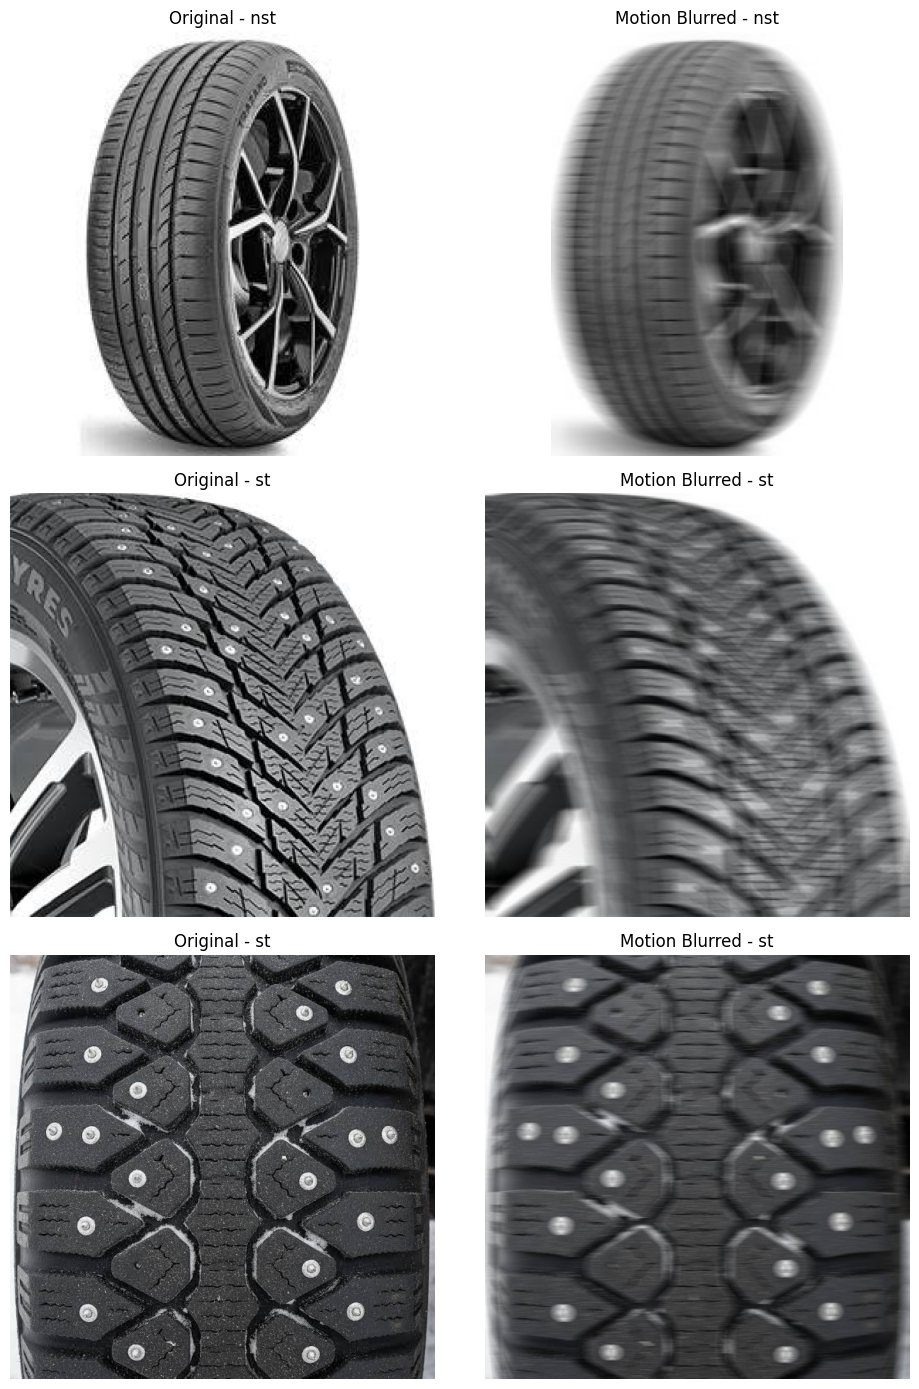

Saved: /content/results/motion_blur_examples.png


In [20]:
# Display 3 original and motion-blurred examples

import matplotlib.pyplot as plt
import cv2
from pathlib import Path

classes_to_show = ["nst", "st", "st"]

fig, axes = plt.subplots(3, 2, figsize=(10, 14))

for i, class_name in enumerate(classes_to_show):

    original_folder = original_test_path / class_name
    blurred_folder = blurred_test_path / class_name

    files = sorted([
        f for f in original_folder.iterdir()
        if f.suffix.lower() in image_extensions
    ])

    image_file = files[i]  # Select deterministic examples

    original_img = cv2.imread(str(image_file))
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

    blurred_img = cv2.imread(
        str(blurred_folder / image_file.name)
    )
    blurred_img = cv2.cvtColor(blurred_img, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(original_img)
    axes[i, 0].set_title(f"Original - {class_name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(blurred_img)
    axes[i, 1].set_title(f"Motion Blurred - {class_name}")
    axes[i, 1].axis("off")

plt.tight_layout()

plt.savefig(
    "/content/results/motion_blur_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: /content/results/motion_blur_examples.png")

In [21]:
# PART 4: Wiener Deconvolution Restoration

import cv2
import numpy as np
import os
from pathlib import Path
from skimage.restoration import wiener

# Input: motion-blurred dataset
blurred_path = Path("/content/motion_blurred/test")

# Output: restored images (separate from blurred images)
restored_path = Path("/content/wiener_restored/test")

# Use the same 15x15 motion blur kernel from Part 3
kernel_size = 15

motion_kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
motion_kernel[kernel_size // 2, :] = 1
motion_kernel /= motion_kernel.sum()

# Wiener restoration parameter
balance = 0.01

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

total_restored = 0

for class_folder in blurred_path.iterdir():

    if not class_folder.is_dir():
        continue

    class_name = class_folder.name

    output_class_folder = restored_path / class_name
    output_class_folder.mkdir(parents=True, exist_ok=True)

    for image_file in class_folder.iterdir():

        if image_file.suffix.lower() not in image_extensions:
            continue

        # Load blurred image
        image = cv2.imread(str(image_file))

        if image is None:
            continue

        # Convert to RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Normalize image to range 0-1
        image_float = image.astype(np.float32) / 255.0

        # Restore each color channel separately
        restored_channels = []

        for channel in range(3):

            restored_channel = wiener(
                image_float[:, :, channel],
                motion_kernel,
                balance=balance,
                clip=False
            )

            restored_channels.append(restored_channel)

        # Combine restored channels
        restored_image = np.stack(
            restored_channels,
            axis=2
        )

        # Clip values and convert back to 8-bit
        restored_image = np.clip(
            restored_image,
            0,
            1
        )

        restored_image = (
            restored_image * 255
        ).astype(np.uint8)

        # Convert back to BGR for saving
        restored_image = cv2.cvtColor(
            restored_image,
            cv2.COLOR_RGB2BGR
        )

        # Save restoration
        output_file = output_class_folder / image_file.name

        cv2.imwrite(
            str(output_file),
            restored_image
        )

        total_restored += 1

print("Wiener restoration completed!")
print("Total restored images:", total_restored)
print("Saved to:", restored_path)
print("Wiener balance parameter:", balance)

Wiener restoration completed!
Total restored images: 74
Saved to: /content/wiener_restored/test
Wiener balance parameter: 0.01


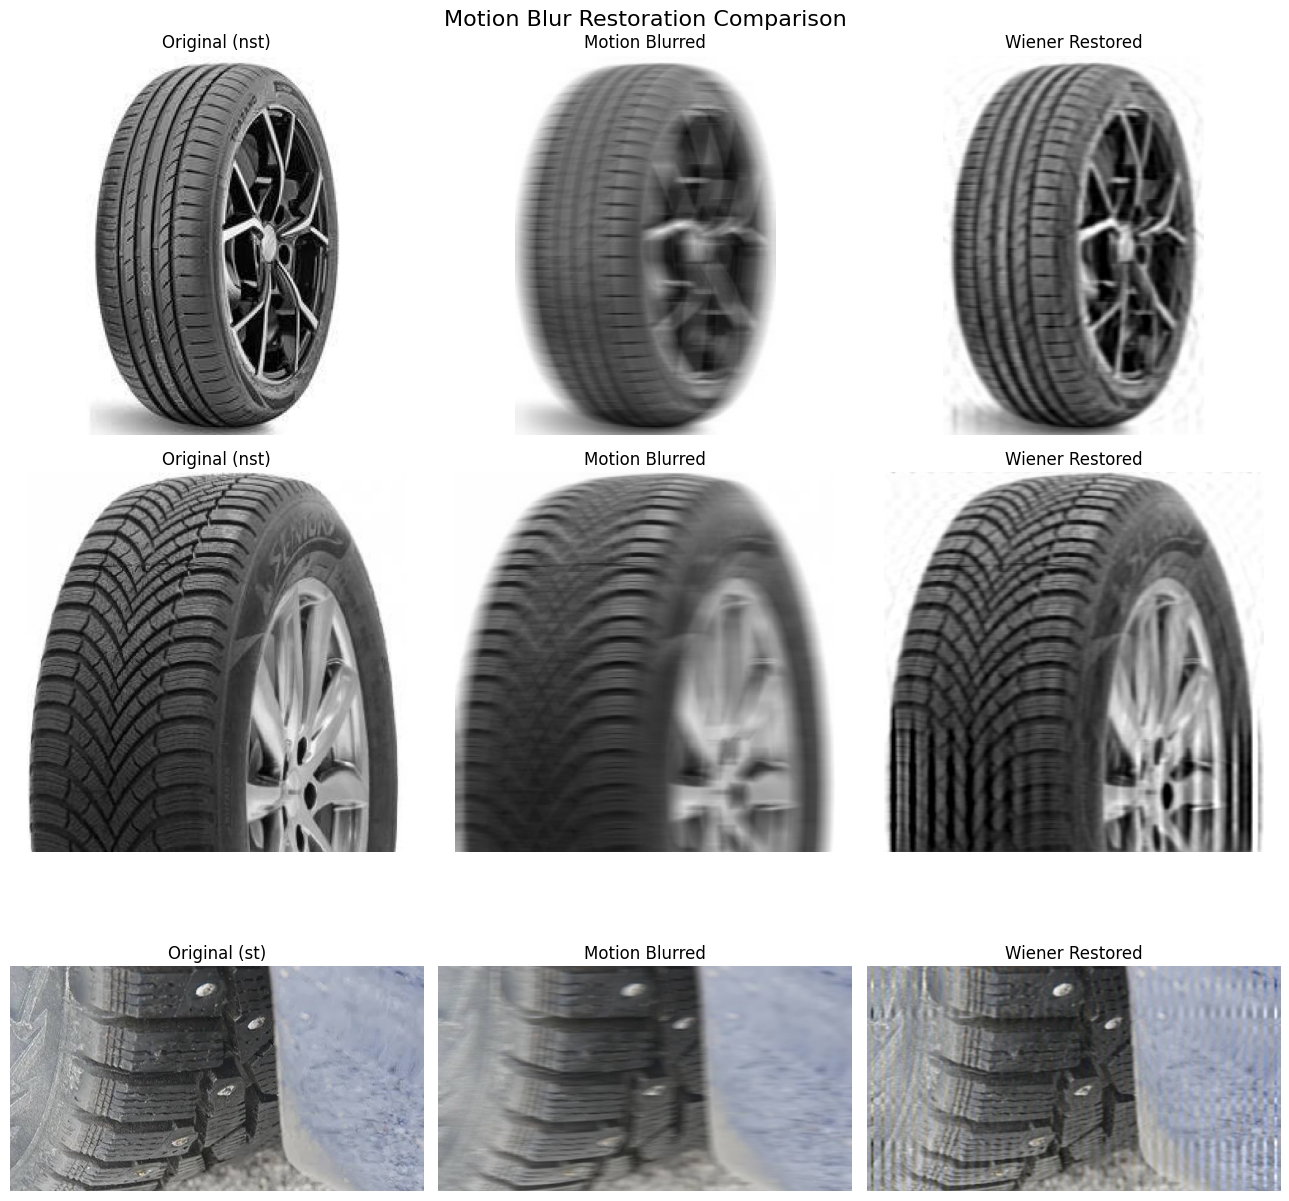

Saved: /content/results/wiener_restoration_examples.png


In [22]:
# Display original, motion-blurred, and Wiener-restored images

import matplotlib.pyplot as plt
import cv2
from pathlib import Path

examples = [
    ("nst", 0),
    ("nst", 1),
    ("st", 0)
]

fig, axes = plt.subplots(3, 3, figsize=(13, 13))

for row, (class_name, index) in enumerate(examples):

    original_folder = original_test_path / class_name
    blurred_folder = blurred_test_path / class_name
    restored_folder = restored_path / class_name

    files = sorted([
        f for f in original_folder.iterdir()
        if f.suffix.lower() in image_extensions
    ])

    image_file = files[index]

    # Load all three versions
    original_img = cv2.imread(str(image_file))
    blurred_img = cv2.imread(str(blurred_folder / image_file.name))
    restored_img = cv2.imread(str(restored_folder / image_file.name))

    # Convert BGR to RGB
    original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
    blurred_img = cv2.cvtColor(blurred_img, cv2.COLOR_BGR2RGB)
    restored_img = cv2.cvtColor(restored_img, cv2.COLOR_BGR2RGB)

    # Display
    axes[row, 0].imshow(original_img)
    axes[row, 0].set_title(f"Original ({class_name})")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(blurred_img)
    axes[row, 1].set_title("Motion Blurred")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(restored_img)
    axes[row, 2].set_title("Wiener Restored")
    axes[row, 2].axis("off")

plt.suptitle(
    "Motion Blur Restoration Comparison",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/results/wiener_restoration_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved: /content/results/wiener_restoration_examples.png")

### Part 4 – Motion Blur Restoration

Wiener restoration was applied to the motion-blurred test images using the same 15 × 15 horizontal motion blur kernel. The restoration improved the visual appearance of some tread patterns and edges compared with the blurred images.

However, the restored images did not fully recover the original image quality. Some details remained blurred, and certain areas showed artifacts or unnatural sharpening. The restoration was based on an assumed blur kernel, which may not perfectly represent the actual degradation.

This experiment demonstrates that traditional restoration can partially reduce motion blur, but it cannot guarantee the recovery of all lost information. Restoration is also more difficult when the actual blur direction, length or intensity is unknown.

In [24]:
# PART 5: Compare YOLO on Original, Blurred and Restored Images

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ---------------------------------------------------
# 1. Define dataset locations
# ---------------------------------------------------

original_path = Path("/content/tire_dataset/dataset_v2_split/test")
blurred_path = Path("/content/motion_blurred/test")
restored_path = Path("/content/wiener_restored/test")

# Class mapping
class_mapping = {
    "nst": 0,  # Non-studded
    "st": 1    # Studded
}

label_names = ["Non-studded", "Studded"]

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# ---------------------------------------------------
# 2. Load model
# ---------------------------------------------------

model = YOLO("/content/best.pt")

print("Loaded model:", model.names)

# ---------------------------------------------------
# 3. Create a consistent list of images and labels
# ---------------------------------------------------

def get_test_images(dataset_path):

    image_paths = []
    labels = []

    for class_name in ["nst", "st"]:

        class_folder = dataset_path / class_name

        files = sorted([
            f for f in class_folder.iterdir()
            if f.is_file() and f.suffix.lower() in image_extensions
        ])

        for image_file in files:

            image_paths.append(str(image_file))
            labels.append(class_mapping[class_name])

    return image_paths, labels


original_images, true_labels = get_test_images(original_path)
blurred_images, blurred_labels = get_test_images(blurred_path)
restored_images, restored_labels = get_test_images(restored_path)

# Verify identical counts and class order
assert len(original_images) == len(blurred_images) == len(restored_images)
assert true_labels == blurred_labels == restored_labels

print("\nNumber of test images:", len(original_images))
print("All three datasets have matching labels.")

# ---------------------------------------------------
# 4. Prediction function
# ---------------------------------------------------

def evaluate_images(image_paths, true_labels, experiment_name):

    predictions = model.predict(
        source=image_paths,
        batch=16,
        verbose=False
    )

    predicted_labels = []

    for result in predictions:

        predicted_index = result.probs.top1
        predicted_name = model.names[predicted_index].lower()

        predicted_labels.append(class_mapping[predicted_name])

    # Positive class = Studded (class 1)
    accuracy = accuracy_score(true_labels, predicted_labels)

    precision = precision_score(
        true_labels,
        predicted_labels,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        true_labels,
        predicted_labels,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        true_labels,
        predicted_labels,
        pos_label=1,
        zero_division=0
    )

    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=[0, 1]
    )

    print("\n" + "=" * 50)
    print(experiment_name)
    print("=" * 50)

    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-score:  {f1:.4f}")

    print("\nClassification report:")
    print(classification_report(
        true_labels,
        predicted_labels,
        labels=[0, 1],
        target_names=label_names,
        zero_division=0
    ))

    print("Confusion matrix:")
    print(cm)

    return {
        "experiment": experiment_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm,
        "predictions": predicted_labels
    }

# ---------------------------------------------------
# 5. Evaluate all three image conditions
# ---------------------------------------------------

original_result = evaluate_images(
    original_images,
    true_labels,
    "YOLO - Original Images"
)

blurred_result = evaluate_images(
    blurred_images,
    true_labels,
    "YOLO - Motion Blurred Images"
)

restored_result = evaluate_images(
    restored_images,
    true_labels,
    "YOLO - Wiener Restored Images"
)

all_results = [
    original_result,
    blurred_result,
    restored_result
]

# ---------------------------------------------------
# 6. Create comparison table
# ---------------------------------------------------

comparison_df = pd.DataFrame([
    {
        "Experiment": r["experiment"],
        "Accuracy": r["accuracy"],
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1-score": r["f1"]
    }
    for r in all_results
])

print("\n===== FINAL COMPARISON =====")

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

# Save table
comparison_df.to_csv(
    "/content/results/yolo_three_way_comparison.csv",
    index=False
)

# ---------------------------------------------------
# 7. Plot all three confusion matrices
# ---------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, result in zip(axes, all_results):

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=result["confusion_matrix"],
        display_labels=label_names
    )

    display_cm.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(result["experiment"])

plt.tight_layout()

plt.savefig(
    "/content/results/yolo_three_confusion_matrices.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print("yolo_three_way_comparison.csv")
print("yolo_three_confusion_matrices.png")

Loaded model: {0: 'nst', 1: 'st'}

Number of test images: 74
All three datasets have matching labels.

YOLO - Original Images
Accuracy:  0.9054
Precision: 0.8409
Recall:    1.0000
F1-score:  0.9136

Classification report:
              precision    recall  f1-score   support

 Non-studded       1.00      0.81      0.90        37
     Studded       0.84      1.00      0.91        37

    accuracy                           0.91        74
   macro avg       0.92      0.91      0.90        74
weighted avg       0.92      0.91      0.90        74

Confusion matrix:
[[30  7]
 [ 0 37]]

YOLO - Motion Blurred Images
Accuracy:  0.7027
Precision: 0.8261
Recall:    0.5135
F1-score:  0.6333

Classification report:
              precision    recall  f1-score   support

 Non-studded       0.65      0.89      0.75        37
     Studded       0.83      0.51      0.63        37

    accuracy                           0.70        74
   macro avg       0.74      0.70      0.69        74
weighted avg    

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [25]:
from IPython.display import display as show_table

# Recreate the comparison table
comparison_df = pd.DataFrame([
    {
        "Experiment": r["experiment"],
        "Accuracy": r["accuracy"],
        "Precision": r["precision"],
        "Recall": r["recall"],
        "F1-score": r["f1"]
    }
    for r in all_results
])

# Display without the previous display() naming conflict
show_table(
    comparison_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}"
    })
)

# Save CSV
comparison_df.to_csv(
    "/content/results/yolo_three_way_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

,Experiment,Accuracy,Precision,Recall,F1-score
0,YOLO - Original Images,90.54%,84.09%,100.00%,91.36%
1,YOLO - Motion Blurred Images,70.27%,82.61%,51.35%,63.33%
2,YOLO - Wiener Restored Images,72.97%,77.42%,64.86%,70.59%


Comparison table saved successfully!


## Part 6 – Final Discussion and Conclusion

Traditional image processing techniques are useful because they are simple, fast and easy to interpret. Grayscale conversion reduces image complexity, CLAHE improves local contrast, Gaussian filtering reduces noise, and Canny edge detection highlights tire boundaries and tread patterns. However, these methods cannot reliably distinguish studded and non-studded tires by themselves. Bright regions, shadows, reflections and tread patterns may produce similar features, making thresholding and edge detection less reliable.

The pretrained YOLO classifier achieved an accuracy of 90.54% on the original test images, with an F1-score of 91.36%. Its recall for studded tires was 100%, meaning all studded tires in the original test set were correctly identified. However, its precision was 84.09%, showing that some non-studded tires were incorrectly classified as studded.

Motion blur significantly reduced classification performance. Accuracy decreased to 70.27%, while recall dropped from 100% to 51.35%. This indicates that motion blur removed or weakened visual information that the model relied on to identify studded tires. Tread details, small metal studs and sharp image features became less visible.

Wiener restoration provided a modest improvement. Accuracy increased from 70.27% to 72.97%, and recall improved from 51.35% to 64.86%. However, restored performance remained below the original baseline. Precision also decreased from 82.61% for blurred images to 77.42% for restored images. This suggests that restoration helped the model identify more studded tires but also introduced or emphasized features that caused additional false positive predictions.

Traditional image processing and deep learning have different strengths. Traditional methods offer control and interpretability, while YOLO can learn complex visual patterns from training data. For a practical tire classification application, I would choose YOLO as the primary classifier, combined with suitable image quality control. Restoration could be considered when images are blurred, but its benefit should be evaluated using classification results rather than visual quality alone.

Overall, the experiment demonstrates that motion blur negatively affects tire classification and that Wiener restoration can partially recover performance, but it cannot completely restore the information lost during degradation.

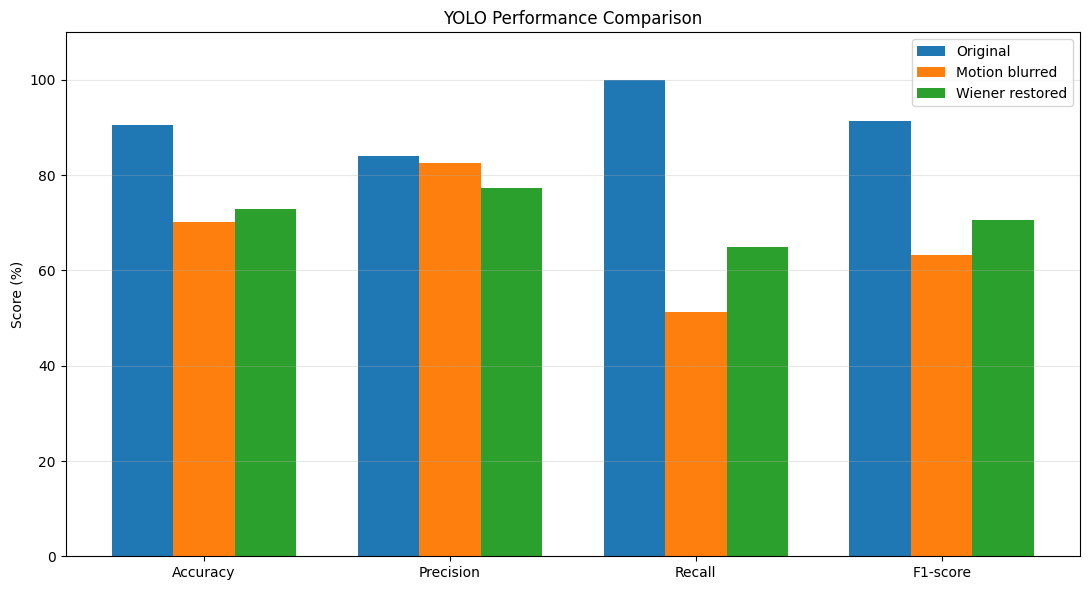

In [26]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

experiments = {
    "Original": [90.54, 84.09, 100.00, 91.36],
    "Motion blurred": [70.27, 82.61, 51.35, 63.33],
    "Wiener restored": [72.97, 77.42, 64.86, 70.59]
}

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

for i, (name, values) in enumerate(experiments.items()):
    ax.bar(x + i * width, values, width, label=name)

ax.set_ylabel("Score (%)")
ax.set_title("YOLO Performance Comparison")
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "/content/results/yolo_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/tire_classification_results",
    "zip",
    "/content/results"
)

files.download("/content/tire_classification_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from ultralytics import YOLO

model = YOLO("/content/best.pt")

print("Your provided YOLO model loaded successfully!")

Your provided YOLO model loaded successfully!


In [ ]:
!pip -q install ultralytics scikit-learn opencv-python-headless scikit-image

In [ ]:
from pathlib import Path
import random, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay
from ultralytics import YOLO
from skimage.restoration import wiener

SEED=42
random.seed(SEED); np.random.seed(SEED)
DATASET_DIR=Path('/content/tire_dataset/test') # EDIT to your test set
MODEL_PATH='/content/tire_classifier.pt'       # EDIT to provided model file
OUT=Path('/content/tire_lab_results')
BLUR=OUT/'blurred'; REST=OUT/'restored'
OUT.mkdir(parents=True,exist_ok=True); BLUR.mkdir(exist_ok=True); REST.mkdir(exist_ok=True)
print('Dataset exists:',DATASET_DIR.exists(),'Model exists:',Path(MODEL_PATH).exists())

### Connect Google Drive (optional)
If your files are stored in Drive, mount it and edit the paths above to their Drive locations.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
EXTS={'.jpg','.jpeg','.png','.bmp','.tif','.tiff','.webp'}
def label_path(p):
    s='/'.join(x.lower().replace('_','-').replace(' ','-') for x in Path(p).parts)
    if 'non-studded' in s or 'nonstudded' in s or 'unstudded' in s or '/non/' in s: return 'non-studded'
    if 'studded' in s: return 'studded'
    return None
paths=sorted(p for p in DATASET_DIR.rglob('*') if p.is_file() and p.suffix.lower() in EXTS) if DATASET_DIR.exists() else []
df=pd.DataFrame([{'path':str(p),'label':label_path(p)} for p in paths])
df=df[df.label.notna()].reset_index(drop=True)
print('Images:',len(df)); display(df.label.value_counts())
if len(df)==0: print('Check DATASET_DIR and class subfolders. Expected labels: studded, non-studded.')

## Part 1 — Traditional preprocessing
Show one image from each class with grayscale, CLAHE, Gaussian filtering, Otsu threshold, Canny edges, and morphological closing.

In [ ]:
def read_bgr(p):
    im=cv2.imread(str(p))
    if im is None: raise ValueError('Cannot read '+str(p))
    return im
def preprocess_one(row):
    bgr=read_bgr(row.path); rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    gray=cv2.cvtColor(bgr,cv2.COLOR_BGR2GRAY)
    clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8)).apply(gray)
    gauss=cv2.GaussianBlur(gray,(5,5),1.2)
    _,th=cv2.threshold(clahe,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    edges=cv2.Canny(gauss,70,150)
    morph=cv2.morphologyEx(edges,cv2.MORPH_CLOSE,np.ones((3,3),np.uint8))
    ims=[rgb,gray,clahe,gauss,th,edges,morph]
    titles=['Original','Grayscale','CLAHE','Gaussian','Otsu threshold','Canny','Morphological closing']
    fig,axs=plt.subplots(1,7,figsize=(21,4))
    for ax,im,t in zip(axs,ims,titles):
        ax.imshow(im,cmap='gray' if im.ndim==2 else None); ax.set_title(t); ax.axis('off')
    fig.suptitle('Class: '+row.label); plt.tight_layout()
    fig.savefig(OUT/f'preprocessing_{row.label}.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)
if len(df):
    for label in ['studded','non-studded']:
        r=df[df.label==label].iloc[0]; preprocess_one(r)

**Observations to write after viewing:** most noticeable operation; whether CLAHE helps stud visibility; what Gaussian removes; whether thresholding separates studs; traditional method limitations.

## Part 2 — YOLO baseline
Use the provided tire-specific YOLO11n-cls weights. Do not retrain. Confirm model class names are the two tire classes.

In [ ]:
if not Path(MODEL_PATH).exists(): raise FileNotFoundError('Upload provided model weights and edit MODEL_PATH.')
model=YOLO(MODEL_PATH)
print('Model labels:',model.names)
def map_label(name):
    s=str(name).lower().replace('_','-').replace(' ','-')
    if 'non' in s or 'unstudded' in s: return 'non-studded'
    if 'studded' in s: return 'studded'
    return None
def predict(p):
    res=model.predict(source=str(p),verbose=False)[0]
    idx=int(res.probs.top1)
    return map_label(model.names[idx]),str(model.names[idx]),float(res.probs.top1conf)
def evaluate(data,tag):
    true=[]; pred=[]; detail=[]
    for _,r in data.iterrows():
        mapped,raw,conf=predict(r.path)
        true.append(r.label); pred.append(mapped)
        detail.append({'path':r.path,'true':r.label,'predicted_label':mapped,'model_label':raw,'confidence':conf})
    valid=[(t,p) for t,p in zip(true,pred) if p is not None]
    if len(valid)!=len(true): print('WARNING: unmapped labels; adjust map_label() to model.names.')
    if not valid: raise ValueError('Model output labels do not match classes. Check weights and map_label().')
    y,p=zip(*valid); labels=['non-studded','studded']
    print(classification_report(y,p,labels=labels,zero_division=0))
    cm=confusion_matrix(y,p,labels=labels)
    ConfusionMatrixDisplay(cm,display_labels=labels).plot(cmap='Blues',values_format='d')
    plt.title(tag); plt.tight_layout(); plt.savefig(OUT/f'confusion_{tag.replace(" ","_")}.png',dpi=180); plt.show()
    m={'Experiment':tag,'Accuracy':accuracy_score(y,p),'Precision_macro':precision_score(y,p,average='macro',zero_division=0),'Recall_macro':recall_score(y,p,average='macro',zero_division=0),'F1_macro':f1_score(y,p,average='macro',zero_division=0)}
    return m,pd.DataFrame(detail),cm
if len(df):
    baseline,baseline_pred,baseline_cm=evaluate(df,'Original')

## Part 3 — Motion blur (15×15 horizontal)
Apply a normalized horizontal kernel to copies, preserve originals, and show three examples.

In [ ]:
K=np.zeros((15,15),np.float32); K[7,:]=1/15
blur_rows=[]
for _,r in df.iterrows():
    src=Path(r.path); rel=src.relative_to(DATASET_DIR); dst=BLUR/rel; dst.parent.mkdir(parents=True,exist_ok=True)
    b=cv2.filter2D(read_bgr(src),-1,K,borderType=cv2.BORDER_REPLICATE); cv2.imwrite(str(dst),b)
    blur_rows.append({'path':str(dst),'label':r.label,'original':r.path})
blur_df=pd.DataFrame(blur_rows)
sample=df.sample(min(3,len(df)),random_state=SEED)
fig,axs=plt.subplots(len(sample),2,figsize=(9,4*len(sample)))
if len(sample)==1: axs=np.array([axs])
for i,(_,r) in enumerate(sample.iterrows()):
    a=cv2.cvtColor(read_bgr(r.path),cv2.COLOR_BGR2RGB); b=cv2.cvtColor(read_bgr(BLUR/Path(r.path).relative_to(DATASET_DIR)),cv2.COLOR_BGR2RGB)
    axs[i,0].imshow(a); axs[i,0].set_title('Original'); axs[i,0].axis('off')
    axs[i,1].imshow(b); axs[i,1].set_title('Motion blur 15×15'); axs[i,1].axis('off')
plt.tight_layout(); plt.savefig(OUT/'motion_blur_examples.png',dpi=180); plt.show()

**Observations:** appearance, details lost, why studs are harder to identify, and whether the blur affects images differently.

## Part 4 — Wiener restoration
Use the same assumed kernel and regularization parameter. Restoration can introduce artifacts and does not guarantee recovering lost information.

In [ ]:
def restore(img, balance=0.02):
    outs=[]
    for ch in cv2.split(img):
        arr=ch.astype(np.float32)/255
        rec=wiener(arr,K,balance=balance,clip=False)
        outs.append(np.uint8(np.clip(rec,0,1)*255))
    return cv2.merge(outs)
rest_rows=[]
for _,r in blur_df.iterrows():
    src=Path(r.path); rel=src.relative_to(BLUR); dst=REST/rel; dst.parent.mkdir(parents=True,exist_ok=True)
    restored=restore(read_bgr(src)); cv2.imwrite(str(dst),restored)
    rest_rows.append({'path':str(dst),'label':r.label,'original':r.original,'blurred':r.path})
rest_df=pd.DataFrame(rest_rows)
fig,axs=plt.subplots(len(sample),3,figsize=(12,4*len(sample)))
if len(sample)==1: axs=np.array([axs])
for i,(_,r) in enumerate(sample.iterrows()):
    rel=Path(r.path).relative_to(DATASET_DIR)
    imgs=[read_bgr(r.path),read_bgr(BLUR/rel),read_bgr(REST/rel)]
    titles=['Original','Blurred','Wiener restored']
    for j,(im,t) in enumerate(zip(imgs,titles)):
        axs[i,j].imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB)); axs[i,j].set_title(t); axs[i,j].axis('off')
plt.tight_layout(); plt.savefig(OUT/'wiener_examples.png',dpi=180); plt.show()

**Observations:** visual improvement, unrecovered details, artifacts, and why unknown kernels make restoration difficult.

## Part 5 — YOLO on original, blurred and restored
Evaluate the same held-out images using the same weights, no training.

In [ ]:
blur_metrics,blur_predictions,blur_cm=evaluate(blur_df,'Motion blurred')
rest_metrics,rest_predictions,rest_cm=evaluate(rest_df,'Wiener restored')
comparison=pd.DataFrame([baseline,blur_metrics,rest_metrics])
comparison=comparison.rename(columns={'Precision_macro':'Precision','Recall_macro':'Recall','F1_macro':'F1'})
display(comparison)
comparison.to_csv(OUT/'metrics_comparison.csv',index=False)
baseline_pred.to_csv(OUT/'predictions_original.csv',index=False)
blur_predictions.to_csv(OUT/'predictions_blurred.csv',index=False)
rest_predictions.to_csv(OUT/'predictions_restored.csv',index=False)

## Part 6 — Discussion (300–500 words)
Write this in your own words after reviewing the actual metrics. Discuss:
- Traditional preprocessing advantages and limitations.
- Difference between fixed image processing operations and YOLO learned features.
- Blur effects on both.
- Whether Wiener restoration changed classifier performance (use measured results).
- Your practical choice, justified by the results.

Do not fabricate metrics. Visual quality and classification scores may not move together.

## Export checklist
- Run all cells with the course dataset and provided model.
- Confirm labels and model class names map correctly.
- Notebook outputs visible; download the `.ipynb`.
- Download `/content/tire_lab_results` (figures, confusion matrices, CSV predictions/metrics).
- Add selected outputs and README to GitHub; **do not upload the original dataset**.
